# Data-driven power curve from SCADA — what wind operators actually do

Every wind turbine streams **SCADA** data: 10-minute averages of wind speed, power, rotor speed,
pitch, temperature. Turning that into a trustworthy **power curve** --- the map from wind speed to
power --- is a core operational task: it sets energy forecasts, spots under-performance, and prices
power purchase agreements. We do it with data alone (no aerodynamics), and meet the data-driven
themes head-on:

1. real SCADA is a **scatter**, not a line --- and the **method of bins** (the IEC standard),
2. an **ML surrogate** that uses extra signals (turbulence, air density) beats binning,
3. **overfitting vs generalization** --- the bias--variance trade-off on the power curve,
4. the **out-of-distribution / curtailment cliff** --- where any data-only model fails.

Ground truth is the Chapter-1 turbine power curve.

### Setup — turbine constants and the ideal steady power curve

Import NumPy/PyTorch/Matplotlib, fix seeds, and define the **ground-truth steady power curve** used
as the noise-free reference. It is the ideal region-II cube capped at rated,
$$P(v)=\min\!\Big(\tfrac12\,\rho\,A\,C_{p,\max}\,v^3,\ P_\text{rated}\Big),$$
with the Chapter-1 turbine constants $\rho_0=1.225$ kg/m³, $R=63$ m (so swept area $A=\pi R^2$),
$C_{p,\max}=0.48$, and $P_\text{rated}=5$ MW. `steady_power(v, rho)` evaluates this and is the
building block for the synthetic SCADA generator.

In [1]:
import sys, os
sys.path.insert(0, os.path.abspath(os.path.join('..', '..')))  # -> python/
import numpy as np, torch, torch.nn as nn
import matplotlib.pyplot as plt
from pyutils import set_plot_style; set_plot_style()
torch.set_default_dtype(torch.float64); torch.manual_seed(0); np.random.seed(0)

FIG = os.path.abspath(os.path.join('..', 'figures')); os.makedirs(FIG, exist_ok=True)
from pyutils import save_dual, fg, muted

# turbine (same benchmark as Chapter 1)
rho0, R, Cp_max, P_rated = 1.225, 63.0, 0.48, 5.0e6
A = np.pi * R**2
def steady_power(v, rho=rho0):
    return np.clip(0.5*rho*A*Cp_max*v**3, 0, P_rated)

*No output — definitions only.* Leaves the turbine constants and the function `steady_power(v, rho)`
in scope. Note the $\min(\cdot,\,P_\text{rated})$: the true curve **saturates** at $5$ MW — the very
plateau the below-rated surrogate of §4 will fail to anticipate.

## 1. Realistic SCADA data, and the method of bins

A 10-minute SCADA record is an **average** over fluctuating wind, so its power is the mean of the
instantaneous curve over the within-window turbulence — which *lifts* region-II points (the cube is
convex there) and *lowers* near-rated points. The generator `make_scada` draws $n=2500$ samples:
wind from a **Weibull($k=2.1$, scale $9.5$)** resource clipped to $[3,25]$ m/s, turbulence intensity
$\mathrm{TI}\sim\mathcal U(0.04,0.18)$, air density $\rho=\rho_0(1+0.04\,\mathcal N)$,
$2\%$-of-rated measurement noise, and $\sim\!6\%$ **curtailment** outliers (operator caps power for
grid/noise reasons). The IEC **method of bins** then averages power in $0.5$ m/s wind-speed bins
(bins with $<3$ points skipped, curtailed points excluded).

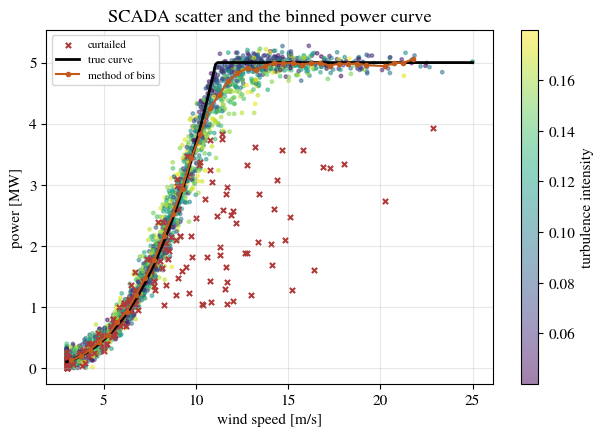

2338 normal points, 162 curtailed


In [2]:
def make_scada(n=2500, seed=0, curtail_frac=0.06):
    rng = np.random.default_rng(seed)
    v = rng.weibull(2.1, n) * 9.5; v = np.clip(v, 3.0, 25.0)          # Weibull wind resource
    TI = rng.uniform(0.04, 0.18, n)                                   # turbulence intensity
    rho = rho0 * (1 + 0.04*rng.standard_normal(n))                    # air density variation
    P = np.empty(n)
    for i in range(n):                                               # 10-min mean over turbulence
        sub = v[i] + TI[i]*v[i]*rng.standard_normal(12)
        P[i] = steady_power(np.clip(sub, 0, None), rho[i]).mean()
    P += 0.02*P_rated*rng.standard_normal(n)                          # measurement noise
    cur = rng.random(n) < curtail_frac                               # curtailment outliers
    P[cur] = np.minimum(P[cur], rng.uniform(0.2, 0.8, cur.sum())*P_rated)
    return v, TI, rho, np.clip(P, 0, None), cur

v, TI, rho, P, cur = make_scada(seed=1)

# method of bins (IEC): mean power per 0.5 m/s bin (skip empty bins)
edges = np.arange(3, 25.01, 0.5); ctr = 0.5*(edges[:-1]+edges[1:])
binc, binP = [], []
for k in range(len(ctr)):
    sel = P[(~cur) & (v >= edges[k]) & (v < edges[k+1])]
    if len(sel) >= 3: binc.append(ctr[k]); binP.append(sel.mean())
binc, binP = np.array(binc), np.array(binP)

def plot_wind_scada():
    fig, ax = plt.subplots(figsize=(7.2, 4.6))
    sc = ax.scatter(v[~cur], P[~cur]/1e6, s=6, c=TI[~cur], cmap='viridis', alpha=0.5)
    ax.scatter(v[cur], P[cur]/1e6, s=14, c='C3', marker='x', label='curtailed')
    ax.plot(np.linspace(3, 25, 200), steady_power(np.linspace(3, 25, 200))/1e6, '-', color=fg(), lw=2, label='true curve')
    ax.plot(binc, binP/1e6, 'C1o-', ms=3, label='method of bins')
    plt.colorbar(sc, label='turbulence intensity'); ax.legend(fontsize=8)
    ax.set(xlabel='wind speed [m/s]', ylabel='power [MW]', title='SCADA scatter and the binned power curve')

save_dual(plot_wind_scada, 'wind_scada', FIG)
plt.show()
print(f'{(~cur).sum()} normal points, {cur.sum()} curtailed')

The print reports **2338 normal points and 162 curtailed** (out of 2500). In the figure the normal
cloud (colored by turbulence intensity) rises cubically and saturates near $5$ MW, closely hugging
the true curve (black); the **method of bins** (orange) recovers that curve well, dipping only
slightly below near rated. The **curtailed** points (red ×) form a distinct low-power band at $1$–$4$
MW between $12$–$23$ m/s — a different operating mode any wind-speed-only model will mispredict.
Leaves `v, TI, rho, P, cur` and the binned curve `binc, binP`.

## 2. An ML surrogate that uses more than wind speed

Binning throws away everything but wind speed, yet the scatter *at a given speed* is largely
explained by **turbulence** and **air density** — signals SCADA already logs. Split one synthetic year's normal records 85 / 15 into **training and validation**, train three predictors
on the training records, and score each on an independent year (`make_scada(seed=7)`), the **test set**: the binned
curve (looked up by wind speed), an MLP on $v$ alone, and an MLP on $(v,\mathrm{TI},\rho)$
(`Linear→48→48→1`, tanh, Adam `lr=3e-3`, 3000 steps, target $P/P_\text{rated}$). Held-out RMSE
measures whether the extra features pay off.

records  train=1988  validation=350  test (independent year)=2345  curtailed, excluded=162  test-out (v >= 12 m/s, section 4)=466


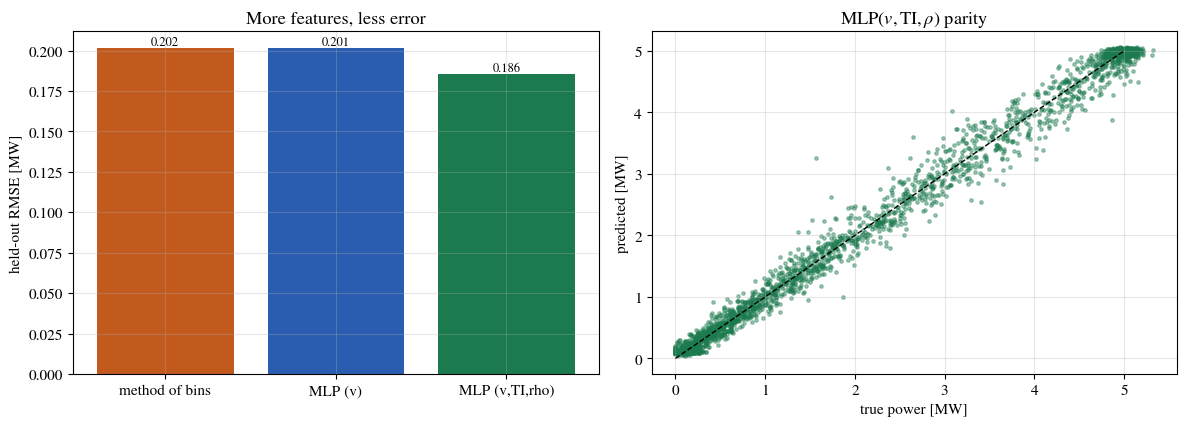

{'method of bins': 0.202, 'MLP (v)': 0.201, 'MLP (v,TI,rho)': 0.186}


In [3]:
mask = ~cur                                                       # normal operation only
# --- the split: 85 / 15 of one synthetic year into train / validation; an independent year is the test set
rng_s = np.random.default_rng(0); idx = rng_s.permutation(np.where(mask)[0]); n_va = int(0.15 * len(idx))
train_sel = np.zeros_like(mask); train_sel[idx[n_va:]] = True
val_sel   = np.zeros_like(mask); val_sel[idx[:n_va]] = True
def fit(features, seed=0, steps=3000, sel=None):
    sel = train_sel if sel is None else sel
    torch.manual_seed(seed)
    X = np.stack(features, 1)[sel]; y = (P[sel]/P_rated)[:, None]
    xm, xs = X.mean(0), X.std(0)+1e-9
    Xt = torch.tensor((X-xm)/xs); yt = torch.tensor(y)
    net = nn.Sequential(nn.Linear(X.shape[1], 48), nn.Tanh(), nn.Linear(48, 48), nn.Tanh(), nn.Linear(48, 1))
    opt = torch.optim.Adam(net.parameters(), 3e-3)
    for _ in range(steps):
        opt.zero_grad(); loss = ((net(Xt)-yt)**2).mean(); loss.backward(); opt.step()
    def predict(feats):
        Xp = (np.stack(feats, 1)-xm)/xs
        with torch.no_grad(): return net(torch.tensor(Xp)).numpy().ravel()*P_rated
    return predict

vt, TIt, rhot, Pt, curt = make_scada(seed=7)                     # test set: an independent year
mt = ~curt
print(f'records  train={train_sel.sum()}  validation={val_sel.sum()}  test (independent year)={mt.sum()}  '
      f'curtailed, excluded={cur.sum()}  test-out (v >= 12 m/s, section 4)={(mt & (vt >= 12)).sum()}')
pred_v = fit([v])([vt])
pred_all = fit([v, TI, rho])([vt, TIt, rhot])
# binned-curve prediction = look up bin power at test wind speed
pred_bin = np.interp(vt, binc, binP)
def rmse(p): return np.sqrt(np.mean((p[mt]-Pt[mt])**2))/1e6
errs = {'method of bins': rmse(pred_bin), 'MLP (v)': rmse(pred_v), 'MLP (v,TI,rho)': rmse(pred_all)}

def plot_wind_features():
    fig, ax = plt.subplots(1, 2, figsize=(12, 4.4))
    ax[0].bar(list(errs), list(errs.values()), color=['C1', 'C0', 'C2'])
    for i, val in enumerate(errs.values()): ax[0].text(i, val, f'{val:.3f}', ha='center', va='bottom', fontsize=9)
    ax[0].set(ylabel='held-out RMSE [MW]', title='More features, less error')
    ax[1].scatter(Pt[mt]/1e6, pred_all[mt]/1e6, s=6, alpha=0.4, color='C2')
    ax[1].plot([0, 5], [0, 5], '--', color=fg(), lw=1)
    ax[1].set(xlabel='true power [MW]', ylabel='predicted [MW]', title='MLP$(v,$TI$,\\rho)$ parity')
    plt.tight_layout()

save_dual(plot_wind_features, 'wind_features', FIG)
plt.show()
print({k: round(val, 3) for k, val in errs.items()})

The split is **1,988 training and 350 validation records** from one year, **2,345 test records** from an independent year, with the 162 curtailed records excluded. Held-out test RMSE: **method of bins $0.202$ MW, MLP($v$) $0.201$ MW, MLP($v,\mathrm{TI},\rho$) $0.186$ MW** — adding turbulence and density cuts the error by $\sim\!8\%$ below both the binning standard and the wind-speed-only network (which ties the bins, since it carries the same information). The parity panel for MLP($v,\mathrm{TI},\rho$) sits tightly on the diagonal across $0$–$5$ MW. Feature engineering, not more capacity, is what buys the improvement here.

## 3. Overfitting vs generalization

With only a **small commissioning dataset** — 50 random 10-minute records — sweep network width
(capacity) over $\{1,2,4,\dots,256\}$ and compare **training RMSE** against **validation RMSE** (each
averaged over 6 seeds for a clean curve; here the model uses $v$ alone). The width with the lowest validation error is then scored **once** on the independent test year. This is the bias–variance
trade-off: extra capacity lets a flexible model chase SCADA noise. The power curve is smooth, so even
the smallest model already has low bias.

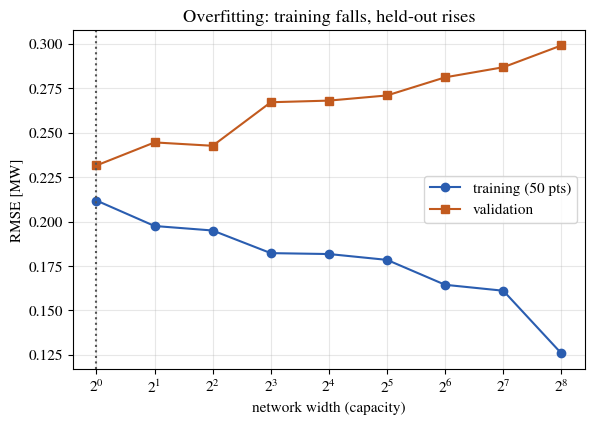

validation RMSE by width: {1: 0.232, 2: 0.244, 4: 0.243, 8: 0.267, 16: 0.268, 32: 0.271, 64: 0.281, 128: 0.287, 256: 0.299}
width selected by validation: 1;  its test RMSE (independent year, reported once): 0.219 MW


In [4]:
def fit_width_once(width, seed, steps=4000):
    rng = np.random.default_rng(seed); sub = rng.choice(np.where(train_sel)[0], 50, replace=False)
    torch.manual_seed(seed)
    X = v[sub][:, None]; y = (P[sub]/P_rated)[:, None]
    xm, xs = X.mean(0), X.std(0)+1e-9
    Xt = torch.tensor((X-xm)/xs); yt = torch.tensor(y)
    net = nn.Sequential(nn.Linear(1, width), nn.Tanh(), nn.Linear(width, width), nn.Tanh(), nn.Linear(width, 1))
    opt = torch.optim.Adam(net.parameters(), 5e-3)
    for _ in range(steps):
        opt.zero_grad(); ((net(Xt)-yt)**2).mean().backward(); opt.step()
    with torch.no_grad():
        tr = float(((net(Xt)-yt)**2).mean())**0.5*P_rated/1e6
        Xv = torch.tensor((v[val_sel][:, None]-xm)/xs)                        # validation, not test
        va = float(((net(Xv).numpy().ravel()*P_rated - P[val_sel])**2).mean())**0.5/1e6
        Xq = torch.tensor((vt[mt][:, None]-xm)/xs)
        te = float(((net(Xq).numpy().ravel()*P_rated - Pt[mt])**2).mean())**0.5/1e6
    return tr, va, te

def fit_width(width, seeds=range(6)):                            # average over seeds -> clean curve
    res = np.array([fit_width_once(width, s) for s in seeds])
    return res[:, 0].mean(), res[:, 1].mean(), res[:, 2].mean()

widths = [1, 2, 4, 8, 16, 32, 64, 128, 256]
tr_e, va_e, te_e = zip(*[fit_width(w) for w in widths])
best_w = widths[int(np.argmin(va_e))]

def plot_wind_overfit():
    fig, ax = plt.subplots(figsize=(6.6, 4.4))
    ax.plot(widths, tr_e, 'o-', label='training (50 pts)'); ax.plot(widths, va_e, 's-', label='validation')
    ax.axvline(best_w, ls=':', color=muted())
    ax.set_xscale('log', base=2); ax.set(xlabel='network width (capacity)', ylabel='RMSE [MW]',
                                          title='Overfitting: training falls, held-out rises'); ax.legend()

save_dual(plot_wind_overfit, 'wind_overfit', FIG)
plt.show()
print('validation RMSE by width:', {w: round(float(e), 3) for w, e in zip(widths, va_e)})
print(f'width selected by validation: {best_w};  its test RMSE (independent year, reported once): {te_e[widths.index(best_w)]:.3f} MW')

Classic overfitting: **training RMSE falls monotonically** with width while **validation RMSE rises** from **$0.232$ MW (width 1) to $0.299$ MW (width 256)**, so the generalization gap widens with capacity. Validation selects the **smallest** model, width 1, and its test RMSE on the independent year — reported once — is **$0.219$ MW**. Because the curve is smooth, low bias comes cheap and the extra capacity only fits noise: validation, never training error and never the test set, is what selects the model.

## 4. The out-of-distribution / curtailment cliff

A data-only surrogate is trustworthy only inside its training envelope. Train on **below-rated data
only** ($v<12$ m/s, `Linear→32→32→1`, tanh) so the model has never seen the rated plateau, then
extrapolate above $12$ m/s. With no mechanism telling it that power saturates, the network simply
continues its local polynomial trend. The prediction is compared against the true saturating curve
and the unseen $v\ge12$ m/s points.

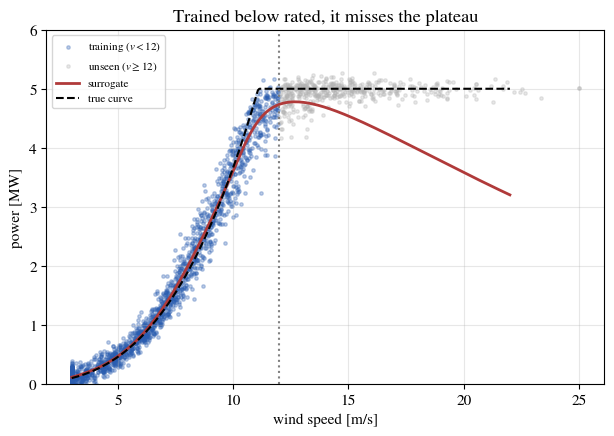

predicted power at 18 m/s: 3.98 MW  (true 5.0 MW) -- the surrogate never learned the cap


In [5]:
below = train_sel & (v < 12.0)
torch.manual_seed(0)
X = v[below][:, None]; y = (P[below]/P_rated)[:, None]
xm, xs = X.mean(0), X.std(0)+1e-9
Xt = torch.tensor((X-xm)/xs); yt = torch.tensor(y)
net = nn.Sequential(nn.Linear(1, 32), nn.Tanh(), nn.Linear(32, 32), nn.Tanh(), nn.Linear(32, 1))
opt = torch.optim.Adam(net.parameters(), 5e-3)
for _ in range(3000):
    opt.zero_grad(); ((net(Xt)-yt)**2).mean().backward(); opt.step()
vg = np.linspace(3, 22, 300)
with torch.no_grad(): pg = net(torch.tensor((vg[:, None]-xm)/xs)).numpy().ravel()*P_rated

def plot_wind_ood():
    fig, ax = plt.subplots(figsize=(7.2, 4.6))
    ax.scatter(v[below], P[below]/1e6, s=6, alpha=0.3, color='C0', label='training ($v<12$)')
    ax.scatter(v[mask & (v >= 12)], P[mask & (v >= 12)]/1e6, s=6, alpha=0.3, color='0.7', label='unseen ($v\\geq12$)')
    ax.plot(vg, pg/1e6, 'C3', lw=2, label='surrogate')
    ax.plot(vg, steady_power(vg)/1e6, '--', color=fg(), lw=1.5, label='true curve')
    ax.axvline(12, ls=':', c='gray'); ax.set(ylim=(0, 6))
    ax.set(xlabel='wind speed [m/s]', ylabel='power [MW]', title='Trained below rated, it misses the plateau')
    ax.legend(fontsize=8)

save_dual(plot_wind_ood, 'wind_ood', FIG)
plt.show()
print('predicted power at 18 m/s:', round(float(np.interp(18, vg, pg))/1e6, 2),
      'MW  (true 5.0 MW) -- the surrogate never learned the cap')

Above the $v=12$ m/s cutoff (dotted line) the true curve (dashed) holds flat at $5$ MW while the surrogate (red) rolls over and bends downward: at $18$ m/s it predicts **3.98 MW versus the true 5.0 MW**, and the gap grows with speed. Having never seen the plateau, it extrapolates the wrong shape entirely — the same blindness that mispredicts curtailed points. **Coverage, not cleverness, sets the limits.**

**Lesson.** A purely data-driven power curve is fast and needs no aerodynamics, and an ML
surrogate that exploits SCADA's extra channels beats the IEC binning standard. But it inherits the
data's coverage: it overfits if over-flexible, and it extrapolates disastrously beyond the observed
wind speeds and operating modes. Coverage sets the limit: a data-only model can be trusted only
inside the envelope of operating conditions it was trained on, and it gives no signal when that
envelope is left.